# Retail Revenue Growth Analysis
## Stage 2 — Revenue Growth and Trends

### Objective

This notebook investigates revenue growth in the Online Retail II
dataset (2009–2010).

The analysis will focus on:

- Monthly net merchandise revenue
- Month-over-month revenue growth
- Revenue trends and seasonality
- Identifying strong and weak sales periods
- Understanding the drivers of revenue changes

### Methodology

Revenue will be calculated using the transaction classification
rules established in `01_data_quality.ipynb`.

Gross merchandise sales and merchandise cancellations will be
analysed separately before calculating net merchandise revenue.

December 2009 and December 2010 will be treated as partial
months when comparing monthly performance.

The results represent preliminary merchandise revenue,
not final accounting revenue.

In [1]:
#####Import Python libraries and locate the dataset

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Locate the project folder
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

# Locate the original dataset
file_path = project_root / "data" / "raw" / "online_retail_II.xlsx"

print("Project folder:", project_root)
print("Dataset found:", file_path.exists())

Project folder: /Users/alexandrebaizoukou/Documents/GitHub/retail-revenue-growth-analysis
Dataset found: True


In [2]:
##### Load the retail dataset

df = pd.read_excel(
    file_path,
    sheet_name="Year 2009-2010"
)

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully!
Rows: 525461
Columns: 8


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


In [3]:
##### Prepare the revenue classification

# Create a working copy of the original dataset
df_classified = df.copy()

# Calculate the signed value of each transaction
df_classified["LineValue"] = (
    df_classified["Quantity"] * df_classified["Price"]
)

# Create a default classification
df_classified["RevenueCategory"] = "Other / Review"

print("Rows:", len(df_classified))
print("New columns:", df_classified.columns.tolist())

Rows: 525461
New columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'LineValue', 'RevenueCategory']


In [4]:
####Classify merchandise sales and cancellations
# Identify cancellation invoices
invoice = df_classified["Invoice"].astype("string").str.upper()

is_cancelled = invoice.str.startswith("C", na=False)

# Identify positive and negative quantities
positive_qty = df_classified["Quantity"] > 0
negative_qty = df_classified["Quantity"] < 0

# Identify positive prices
positive_price = df_classified["Price"] > 0

# Classify merchandise sale candidates
df_classified.loc[
    positive_qty & positive_price & ~is_cancelled,
    "RevenueCategory"
] = "Merchandise sale candidate"

# Classify merchandise cancellation candidates
df_classified.loc[
    negative_qty & positive_price & is_cancelled,
    "RevenueCategory"
] = "Merchandise cancellation candidate"

# Display classification results
display(
    df_classified["RevenueCategory"].value_counts()
)

RevenueCategory
Merchandise sale candidate            511565
Merchandise cancellation candidate     10205
Other / Review                          3691
Name: count, dtype: int64

In [5]:
##### Identify zero-price transactions

# Identify zero-price transactions
zero_price = df_classified["Price"] == 0

# Positive-quantity, zero-price records
df_classified.loc[
    positive_qty & zero_price,
    "RevenueCategory"
] = "Zero-price positive transaction"

# Negative-quantity, zero-price records
df_classified.loc[
    negative_qty & zero_price,
    "RevenueCategory"
] = "Zero-price negative adjustment"

# Display updated classification
display(
    df_classified["RevenueCategory"].value_counts()
)

# Verify all records are preserved
assert len(df_classified) == 525461

print("Classification check passed.")

RevenueCategory
Merchandise sale candidate            511565
Merchandise cancellation candidate     10205
Zero-price negative adjustment          2121
Zero-price positive transaction         1566
Other / Review                             4
Name: count, dtype: int64

Classification check passed.


In [6]:
###### Classify manual transactions, postage and bad debt

# Standardise stock codes and descriptions
stock = (
    df_classified["StockCode"]
    .astype("string")
    .str.upper()
    .str.strip()
)

description = (
    df_classified["Description"]
    .astype("string")
    .str.strip()
)

# Postage and delivery
df_classified.loc[
    stock.eq("DOT") |
    description.str.fullmatch(
        r"(?i)DOTCOM POSTAGE", na=False
    ),
    "RevenueCategory"
] = "Postage / delivery"

# Manual transactions
df_classified.loc[
    stock.eq("M"),
    "RevenueCategory"
] = "Manual transaction"

# Bad debt adjustments
df_classified.loc[
    stock.eq("B") &
    description.str.contains(
        "bad debt", case=False, na=False
    ),
    "RevenueCategory"
] = "Bad debt adjustment"

# Test transactions
df_classified.loc[
    stock.eq("TEST001"),
    "RevenueCategory"
] = "Test transaction"

# Review classification
display(
    df_classified["RevenueCategory"].value_counts()
)

print("Special transaction classification completed.")

RevenueCategory
Merchandise sale candidate            510267
Merchandise cancellation candidate      9906
Zero-price negative adjustment          2121
Zero-price positive transaction         1559
Manual transaction                       854
Postage / delivery                       736
Test transaction                          15
Bad debt adjustment                        3
Name: count, dtype: int64

Special transaction classification completed.


In [7]:
##### Classify additional non-merchandise transactions
##### Additional non-merchandise classifications

special_categories = {
    "D": "Discount",
    "S": "Samples / Review",
    "AMAZONFEE": "Marketplace fee",
    "ADJUST": "Accounting adjustment",
    "ADJUST2": "Accounting adjustment",
    "BANK CHARGES": "Bank charges",
}

for code, category in special_categories.items():
    df_classified.loc[
        stock.eq(code).fillna(False),
        "RevenueCategory"
    ] = category

# Additional delivery and carriage codes
df_classified.loc[
    stock.isin(["POST", "DOT", "C2"]).fillna(False),
    "RevenueCategory"
] = "Postage / delivery"

# Gift vouchers
df_classified.loc[
    stock.str.startswith("GIFT_0001_", na=False),
    "RevenueCategory"
] = "Gift voucher / Review"

# Check classification results
display(
    df_classified["RevenueCategory"].value_counts()
)

# Verify no records were lost
assert len(df_classified) == len(df)
assert df_classified["RevenueCategory"].notna().all()

print("Additional classification checks passed.")

RevenueCategory
Merchandise sale candidate            509261
Merchandise cancellation candidate      9582
Zero-price negative adjustment          2121
Postage / delivery                      1739
Zero-price positive transaction         1535
Manual transaction                       854
Discount                                 100
Accounting adjustment                     70
Gift voucher / Review                     66
Bank charges                              65
Samples / Review                          41
Test transaction                          15
Marketplace fee                            9
Bad debt adjustment                        3
Name: count, dtype: int64

Additional classification checks passed.


In [8]:
##### Reconcile revenue with Stage 1
# Select merchandise sales
sales = df_classified.loc[
    df_classified["RevenueCategory"] == "Merchandise sale candidate"
].copy()

# Select merchandise cancellations
cancellations = df_classified.loc[
    df_classified["RevenueCategory"] == "Merchandise cancellation candidate"
].copy()

# Calculate revenue metrics
gross_sales = sales["LineValue"].sum()
cancellation_value = cancellations["LineValue"].sum()
net_merchandise_revenue = gross_sales + cancellation_value

# Display results
print(f"Gross merchandise sales: £{gross_sales:,.2f}")
print(f"Merchandise cancellations: £{cancellation_value:,.2f}")
print(f"Net merchandise revenue: £{net_merchandise_revenue:,.2f}")

# Compare against Stage 1
assert abs(gross_sales - 9838748.95) < 0.01
assert abs(cancellation_value - (-247831.81)) < 0.01
assert abs(net_merchandise_revenue - 9590917.14) < 0.01

print("\nStage 1 and Stage 2 revenue reconciliation passed.")

Gross merchandise sales: £9,838,748.95
Merchandise cancellations: £-247,831.81
Net merchandise revenue: £9,590,917.14

Stage 1 and Stage 2 revenue reconciliation passed.


In [9]:
##### Calculate monthly net revenue

# Keep merchandise sales and cancellations
revenue_data = df_classified.loc[
    df_classified["RevenueCategory"].isin([
        "Merchandise sale candidate",
        "Merchandise cancellation candidate"
    ])
].copy()

# Convert invoice dates to monthly periods
revenue_data["Month"] = (
    pd.to_datetime(revenue_data["InvoiceDate"])
    .dt.to_period("M")
)

# Calculate monthly net merchandise revenue
monthly_revenue = (
    revenue_data.groupby("Month")["LineValue"]
    .sum()
    .reset_index(name="NetRevenue")
    .sort_values("Month")
)

# Display results
display(monthly_revenue)

# Check that monthly totals reconcile
assert abs(
    monthly_revenue["NetRevenue"].sum()
    - net_merchandise_revenue
) < 0.01

print("Monthly revenue reconciliation passed.")

,Month,NetRevenue
0,2009-12,781542.690
1,2010-01,606385.182
2,2010-02,527160.296
3,2010-03,754676.651
4,2010-04,638968.562
5,2010-05,608351.250
6,2010-06,672935.410
7,2010-07,617764.260
8,2010-08,663642.070
9,2010-09,844100.371


Monthly revenue reconciliation passed.


In [10]:
#####Calculate month-on-month revenue growth

# Calculate month-on-month revenue growth
monthly_revenue["MoM_Growth_Pct"] = (
    monthly_revenue["NetRevenue"]
    .pct_change(fill_method=None) * 100
)

# Display monthly growth results
display(
    monthly_revenue.round(2)
)

,Month,NetRevenue,MoM_Growth_Pct
0,2009-12,781542.69,NaN
1,2010-01,606385.18,-22.41
2,2010-02,527160.30,-13.07
3,2010-03,754676.65,43.16
4,2010-04,638968.56,-15.33
5,2010-05,608351.25,-4.79
6,2010-06,672935.41,10.62
7,2010-07,617764.26,-8.20
8,2010-08,663642.07,7.43
9,2010-09,844100.37,27.19


In [11]:
##### Flag incomplete-month comparisons
# Flag month-on-month comparisons requiring caution
monthly_revenue["MoM_Comparable"] = True

# December 2009 is the dataset's starting month
# January 2010 compares against December 2009
# December 2010 is the dataset's ending month
monthly_revenue.loc[
    monthly_revenue["Month"].astype(str).isin([
        "2009-12",
        "2010-01",
        "2010-12"
    ]),
    "MoM_Comparable"
] = False

# Create a growth measure for comparable months only
monthly_revenue["Comparable_MoM_Growth_Pct"] = (
    monthly_revenue["MoM_Growth_Pct"]
    .where(monthly_revenue["MoM_Comparable"])
)

# Display results
display(
    monthly_revenue[
        [
            "Month",
            "MoM_Growth_Pct",
            "MoM_Comparable",
            "Comparable_MoM_Growth_Pct"
        ]
    ].round(2)
)


,Month,MoM_Growth_Pct,MoM_Comparable,Comparable_MoM_Growth_Pct
0,2009-12,NaN,False,NaN
1,2010-01,-22.41,False,NaN
2,2010-02,-13.07,True,-13.07
3,2010-03,43.16,True,43.16
4,2010-04,-15.33,True,-15.33
5,2010-05,-4.79,True,-4.79
6,2010-06,10.62,True,10.62
7,2010-07,-8.20,True,-8.20
8,2010-08,7.43,True,7.43
9,2010-09,27.19,True,27.19


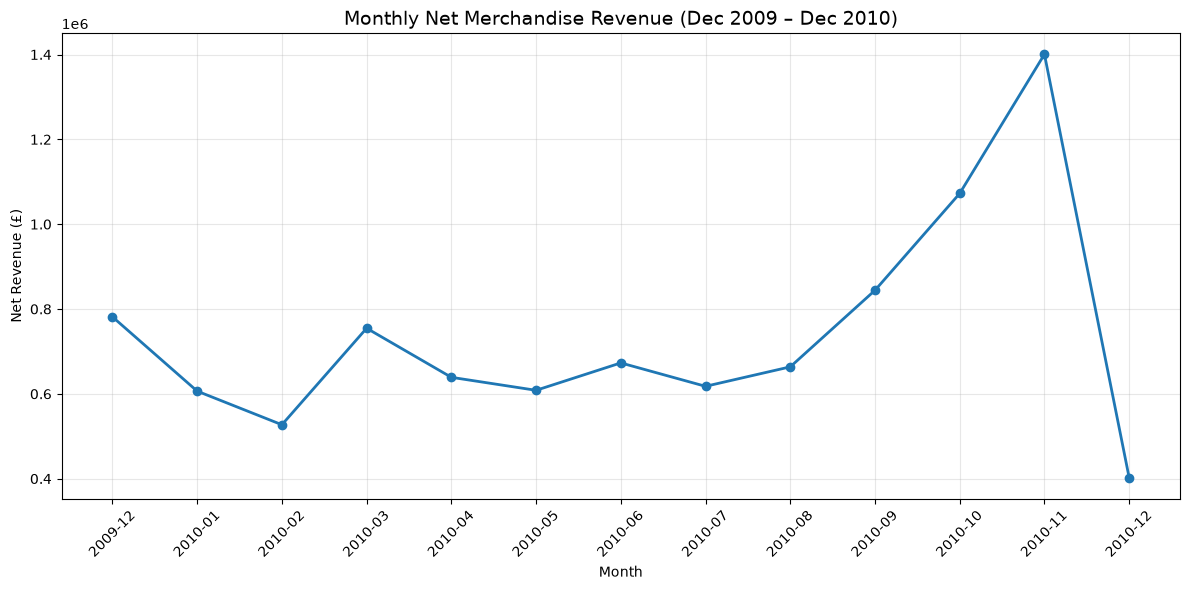

In [12]:
# Prepare monthly revenue chart
chart_data = monthly_revenue.copy()

chart_data["MonthLabel"] = (
    chart_data["Month"].astype(str)
)

# Create chart
plt.figure(figsize=(12, 6))

plt.plot(
    chart_data["MonthLabel"],
    chart_data["NetRevenue"],
    marker="o",
    linewidth=2
)

plt.title(
    "Monthly Net Merchandise Revenue (Dec 2009 – Dec 2010)",
    fontsize=14
)

plt.xlabel("Month")
plt.ylabel("Net Revenue (£)")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

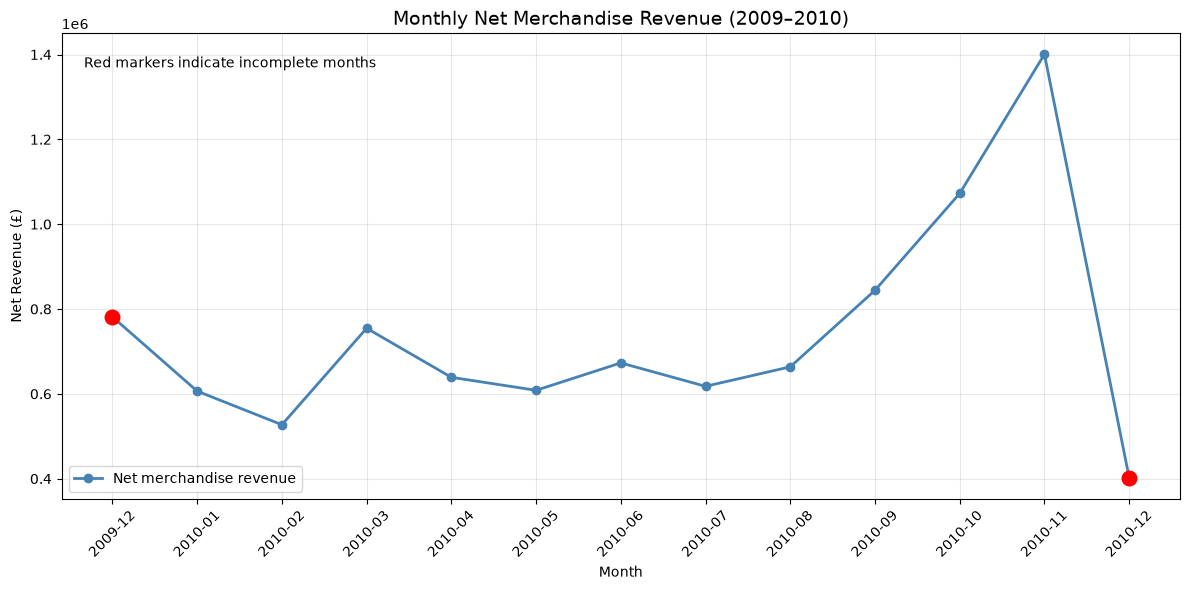

In [13]:
### Highlight incomplete months on the chart

# Create an improved monthly revenue chart
fig, ax = plt.subplots(figsize=(12, 6))

# Plot monthly revenue
ax.plot(
    chart_data["MonthLabel"],
    chart_data["NetRevenue"],
    marker="o",
    linewidth=2,
    color="steelblue",
    label="Net merchandise revenue"
)

# Highlight incomplete months
incomplete_months = ["2009-12", "2010-12"]

for month in incomplete_months:
    row = chart_data.loc[
        chart_data["MonthLabel"] == month
    ]

    ax.scatter(
        row["MonthLabel"],
        row["NetRevenue"],
        color="red",
        s=110,
        zorder=5
    )

# Add explanatory note
ax.text(
    0.02,
    0.95,
    "Red markers indicate incomplete months",
    transform=ax.transAxes,
    fontsize=10,
    verticalalignment="top"
)

ax.set_title(
    "Monthly Net Merchandise Revenue (2009–2010)",
    fontsize=14
)

ax.set_xlabel("Month")
ax.set_ylabel("Net Revenue (£)")

ax.tick_params(axis="x", rotation=45)
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

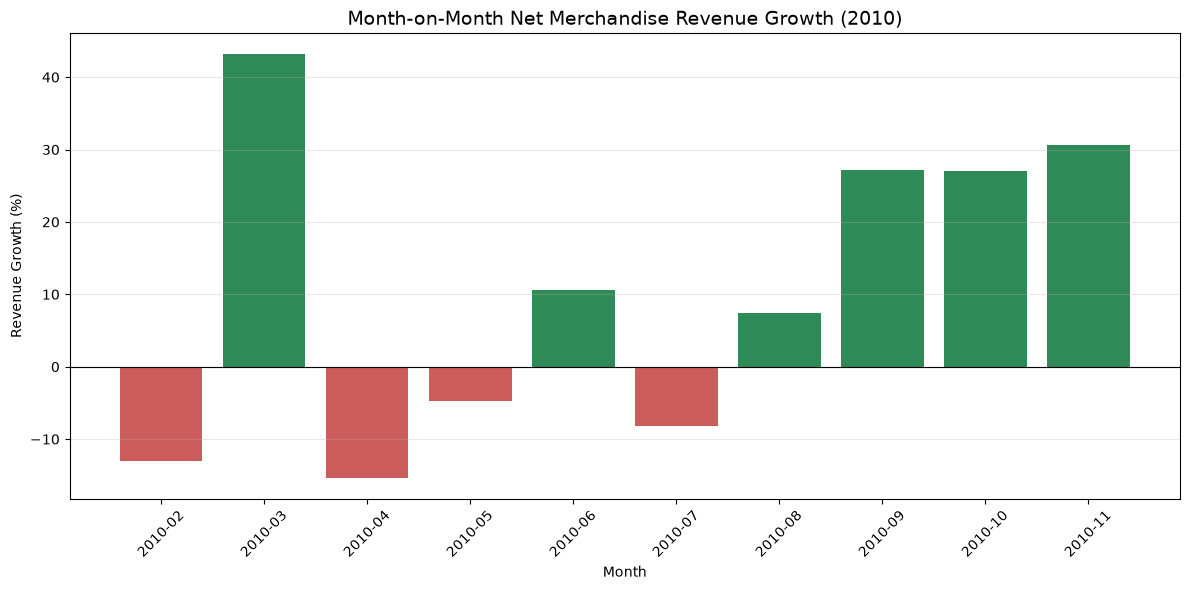

In [14]:
#### Visualise month-on-month revenue growth
# Select comparable months only
growth_data = monthly_revenue.loc[
    monthly_revenue["MoM_Comparable"]
].copy()

# Assign colours based on growth direction
colors = [
    "seagreen" if value >= 0 else "indianred"
    for value in growth_data["Comparable_MoM_Growth_Pct"]
]

# Create bar chart
fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    growth_data["Month"].astype(str),
    growth_data["Comparable_MoM_Growth_Pct"],
    color=colors
)

# Add zero-growth reference line
ax.axhline(0, color="black", linewidth=0.8)

ax.set_title(
    "Month-on-Month Net Merchandise Revenue Growth (2010)",
    fontsize=14
)

ax.set_xlabel("Month")
ax.set_ylabel("Revenue Growth (%)")

ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
#### Measure the revenue increase from August to November
# Extract August and November revenue
august_revenue = monthly_revenue.loc[
    monthly_revenue["Month"].astype(str) == "2010-08",
    "NetRevenue"
].iloc[0]

november_revenue = monthly_revenue.loc[
    monthly_revenue["Month"].astype(str) == "2010-11",
    "NetRevenue"
].iloc[0]

# Calculate absolute and percentage growth
revenue_increase = november_revenue - august_revenue

growth_percentage = (
    revenue_increase / august_revenue
) * 100

# Display results
print(f"August revenue: £{august_revenue:,.2f}")
print(f"November revenue: £{november_revenue:,.2f}")
print(f"Revenue increase: £{revenue_increase:,.2f}")
print(f"Growth percentage: {growth_percentage:.2f}%")

August revenue: £663,642.07
November revenue: £1,400,559.24
Revenue increase: £736,917.17
Growth percentage: 111.04%


In [16]:
sales_volume = sales.copy()

sales_volume["Month"] = pd.to_datetime(
    sales_volume["InvoiceDate"]
).dt.to_period("M")

monthly_units = (
    sales_volume.groupby("Month")["Quantity"]
    .sum()
    .reset_index(name="UnitsSold")
)

display(
    monthly_units[
        monthly_units["Month"].astype(str).isin([
            "2010-08", "2010-09",
            "2010-10", "2010-11"
        ])
    ]
)

,Month,UnitsSold
8,2010-08,472971
9,2010-09,584855
10,2010-10,621610
11,2010-11,727553


In [17]:
##### Measure the revenue increase from August to November
# Extract August and November revenue
august_revenue = monthly_revenue.loc[
    monthly_revenue["Month"].astype(str) == "2010-08",
    "NetRevenue"
].iloc[0]

november_revenue = monthly_revenue.loc[
    monthly_revenue["Month"].astype(str) == "2010-11",
    "NetRevenue"
].iloc[0]

# Calculate absolute and percentage growth
revenue_increase = november_revenue - august_revenue

growth_percentage = (
    revenue_increase / august_revenue
) * 100

# Display results
print(f"August revenue: £{august_revenue:,.2f}")
print(f"November revenue: £{november_revenue:,.2f}")
print(f"Revenue increase: £{revenue_increase:,.2f}")
print(f"Growth percentage: {growth_percentage:.2f}%")


August revenue: £663,642.07
November revenue: £1,400,559.24
Revenue increase: £736,917.17
Growth percentage: 111.04%


In [18]:
##### Calculate sales value per unit

# Calculate monthly gross merchandise sales
monthly_gross_sales = (
    sales_volume.groupby("Month")
    .agg(
        GrossSales=("LineValue", "sum"),
        UnitsSold=("Quantity", "sum")
    )
    .reset_index()
)

# Calculate average sales value per unit
monthly_gross_sales["SalesValuePerUnit"] = (
    monthly_gross_sales["GrossSales"]
    / monthly_gross_sales["UnitsSold"]
)

# Focus on August–November
unit_value_comparison = monthly_gross_sales.loc[
    monthly_gross_sales["Month"].astype(str).isin([
        "2010-08", "2010-09",
        "2010-10", "2010-11"
    ])
]

display(unit_value_comparison.round(2))

,Month,GrossSales,UnitsSold,SalesValuePerUnit
8,2010-08,676060.72,472971,1.43
9,2010-09,871878.34,584855,1.49
10,2010-10,1098017.67,621610,1.77
11,2010-11,1435680.12,727553,1.97


In [19]:
##### Calculate the contribution of volume and unit value

# Select August and November
aug = monthly_gross_sales.loc[
    monthly_gross_sales["Month"].astype(str) == "2010-08"
].iloc[0]

nov = monthly_gross_sales.loc[
    monthly_gross_sales["Month"].astype(str) == "2010-11"
].iloc[0]

# Calculate changes
volume_change = nov["UnitsSold"] - aug["UnitsSold"]
unit_value_change = (
    nov["SalesValuePerUnit"] - aug["SalesValuePerUnit"]
)

# Symmetric decomposition of gross sales growth
volume_effect = volume_change * (
    aug["SalesValuePerUnit"] + nov["SalesValuePerUnit"]
) / 2

unit_value_effect = unit_value_change * (
    aug["UnitsSold"] + nov["UnitsSold"]
) / 2

total_growth = nov["GrossSales"] - aug["GrossSales"]

print(f"Volume effect: £{volume_effect:,.2f}")
print(f"Unit value effect: £{unit_value_effect:,.2f}")
print(f"Total gross sales growth: £{total_growth:,.2f}")

# Verify decomposition
assert abs(
    volume_effect + unit_value_effect - total_growth
) < 0.01

print("Growth decomposition reconciled.")


Volume effect: £433,131.96
Unit value effect: £326,487.44
Total gross sales growth: £759,619.40
Growth decomposition reconciled.


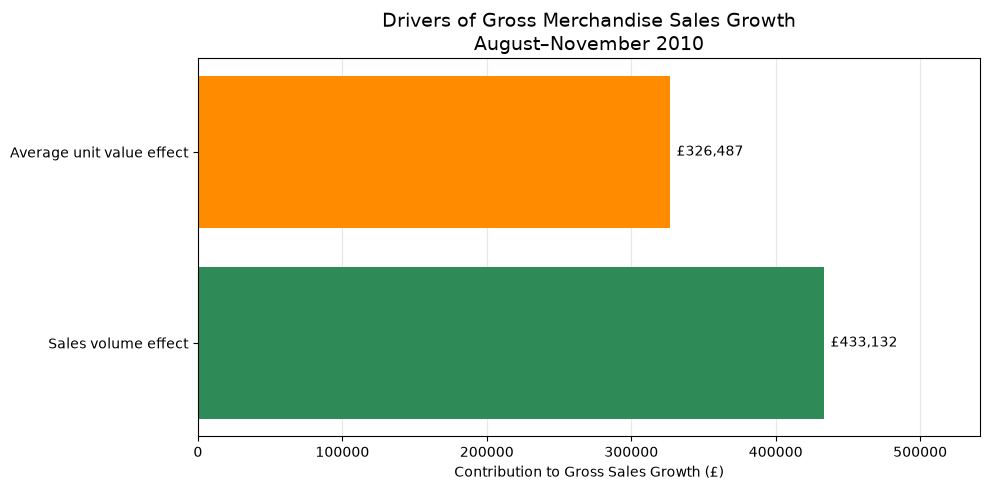

In [20]:
#### Visualise the growth decomposition
# Visualise the contribution of each growth component
components = [
    "Sales volume effect",
    "Average unit value effect"
]

values = [
    volume_effect,
    unit_value_effect
]

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    components,
    values,
    color=["seagreen", "darkorange"]
)

# Display monetary values on bars
ax.bar_label(
    bars,
    labels=[f"£{value:,.0f}" for value in values],
    padding=5
)

ax.set_title(
    "Drivers of Gross Merchandise Sales Growth\n"
    "August–November 2010",
    fontsize=14
)

ax.set_xlabel("Contribution to Gross Sales Growth (£)")
ax.set_xlim(0, max(values) * 1.25)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [21]:
#### Identify the top products in August and November
# Select August and November merchandise sales
product_data = sales_volume.loc[
    sales_volume["Month"].astype(str).isin([
        "2010-08", "2010-11"
    ])
].copy()

# Calculate gross sales by month and product
product_revenue = (
    product_data.groupby(
        ["Month", "StockCode"],
        observed=True
    )
    .agg(
        GrossSales=("LineValue", "sum"),
        UnitsSold=("Quantity", "sum")
    )
    .reset_index()
)

# Rank products by gross sales within each month
product_revenue["Rank"] = (
    product_revenue.groupby("Month")["GrossSales"]
    .rank(method="first", ascending=False)
)

# Display top 10 products for each month
top_products = product_revenue.loc[
    product_revenue["Rank"] <= 10
].sort_values(["Month", "Rank"])

display(top_products)

,Month,StockCode,GrossSales,UnitsSold,Rank
1226,2010-08,22423,13271.28,1046,1.0
2465,2010-08,85123A,12684.23,4708,2.0
1599,2010-08,47566,5502.11,609,3.0
101,2010-08,20725,5457.73,2897,4.0
1784,2010-08,84879,5055.63,3171,5.0
2456,2010-08,85099F,4758.35,2501,6.0
557,2010-08,21523,4563.14,758,7.0
1614,2010-08,48194,4047.45,693,8.0
1030,2010-08,22189,4016.84,1360,9.0
843,2010-08,21931,3879.50,1663,10.0


In [22]:
##### Identify products contributing most to sales growth

# Compare product revenue between August and November
product_growth = product_revenue.pivot_table(
    index="StockCode",
    columns="Month",
    values="GrossSales",
    aggfunc="sum",
    fill_value=0,
    observed=True
)

# Rename monthly columns
product_growth.columns = [
    str(month) for month in product_growth.columns
]

# Calculate absolute revenue growth
product_growth["RevenueGrowth"] = (
    product_growth["2010-11"]
    - product_growth["2010-08"]
)

# Sort by revenue growth
product_growth = product_growth.sort_values(
    "RevenueGrowth",
    ascending=False
)

# Display top 10 contributors
display(product_growth.head(10).round(2))

,2010-08,2010-11,RevenueGrowth
StockCode,,,
22086,776.14,28341.81,27565.67
84347,479.73,25710.94,25231.21
22423,13271.28,28151.33,14880.05
22910,0.00,14276.22,14276.22
22865,0.00,9620.68,9620.68
84879,5055.63,14626.47,9570.84
22866,0.00,9345.34,9345.34
22197,1939.30,10291.52,8352.22
22837,0.00,8130.11,8130.11


In [23]:
#### Measure growth concentration
# Calculate growth from the top 10 products
top_10_growth = (
    product_growth.head(10)["RevenueGrowth"].sum()
)

# Calculate their contribution to total gross sales growth
top_10_contribution = (
    top_10_growth / total_growth
) * 100

# Display results
print(f"Top 10 product growth: £{top_10_growth:,.2f}")
print(f"Total gross sales growth: £{total_growth:,.2f}")
print(f"Top 10 contribution: {top_10_contribution:.2f}%")

# Check product-level reconciliation
assert abs(
    product_growth["RevenueGrowth"].sum()
    - total_growth
) < 0.01

print("Product-level growth reconciliation passed.")

Top 10 product growth: £134,963.81
Total gross sales growth: £759,619.40
Top 10 contribution: 17.77%
Product-level growth reconciliation passed.


In [24]:
# Count products by revenue growth direction
growing_products = (
    product_growth["RevenueGrowth"] > 0
).sum()

declining_products = (
    product_growth["RevenueGrowth"] < 0
).sum()

unchanged_products = (
    product_growth["RevenueGrowth"] == 0
).sum()

total_products = len(product_growth)

# Display results
print(f"Products with revenue growth: {growing_products:,}")
print(f"Products with revenue decline: {declining_products:,}")
print(f"Products with no change: {unchanged_products:,}")
print(f"Total products analysed: {total_products:,}")

# Verify counts
assert (
    growing_products
    + declining_products
    + unchanged_products
    == total_products
)

print("Product growth classification passed.")

Products with revenue growth: 2,257
Products with revenue decline: 1,056
Products with no change: 36
Total products analysed: 3,349
Product growth classification passed.


In [25]:
##### Classify product activity
# Identify products with positive sales in each month
august_active = product_growth["2010-08"] > 0
november_active = product_growth["2010-11"] > 0

# Classify product activity
product_growth["ProductStatus"] = np.select(
    [
        august_active & november_active,
        ~august_active & november_active,
        august_active & ~november_active
    ],
    [
        "Active in both months",
        "November only",
        "August only"
    ],
    default="Neither / Review"
)

# Display results
display(product_growth["ProductStatus"].value_counts())

ProductStatus
Active in both months    2353
November only             670
August only               326
Name: count, dtype: int64

In [26]:
#### Measure revenue from November-only products

# Calculate November gross sales by product activity
status_revenue = (
    product_growth.groupby("ProductStatus")["2010-11"]
    .sum()
    .sort_values(ascending=False)
)

# Calculate each category's share of November sales
status_share = (
    status_revenue / nov["GrossSales"] * 100
)

# Create a summary table
status_summary = pd.DataFrame({
    "NovemberGrossSales": status_revenue,
    "ShareOfNovemberSalesPct": status_share
})

display(status_summary.round(2))

# Verify November sales reconciliation
assert abs(
    status_summary["NovemberGrossSales"].sum()
    - nov["GrossSales"]
) < 0.01

print("November product revenue reconciliation passed.")

,NovemberGrossSales,ShareOfNovemberSalesPct
ProductStatus,,
Active in both months,1145927.48,79.82
November only,289752.64,20.18
August only,0.00,0.00


November product revenue reconciliation passed.


In [27]:
##### Measure the contribution of each product group to growth
# Calculate gross sales growth by product activity
growth_by_status = (
    product_growth.groupby("ProductStatus")["RevenueGrowth"]
    .sum()
    .sort_values(ascending=False)
)

# Calculate contribution to total gross sales growth
growth_share = (
    growth_by_status / total_growth * 100
)

# Create summary table
growth_status_summary = pd.DataFrame({
    "RevenueGrowth": growth_by_status,
    "ContributionPct": growth_share
})

display(growth_status_summary.round(2))

# Verify reconciliation
assert abs(
    growth_status_summary["RevenueGrowth"].sum()
    - total_growth
) < 0.01

print("Product group growth reconciliation passed.")

,RevenueGrowth,ContributionPct
ProductStatus,,
Active in both months,498347.69,65.60
November only,289752.64,38.14
August only,-28480.93,-3.75


Product group growth reconciliation passed.


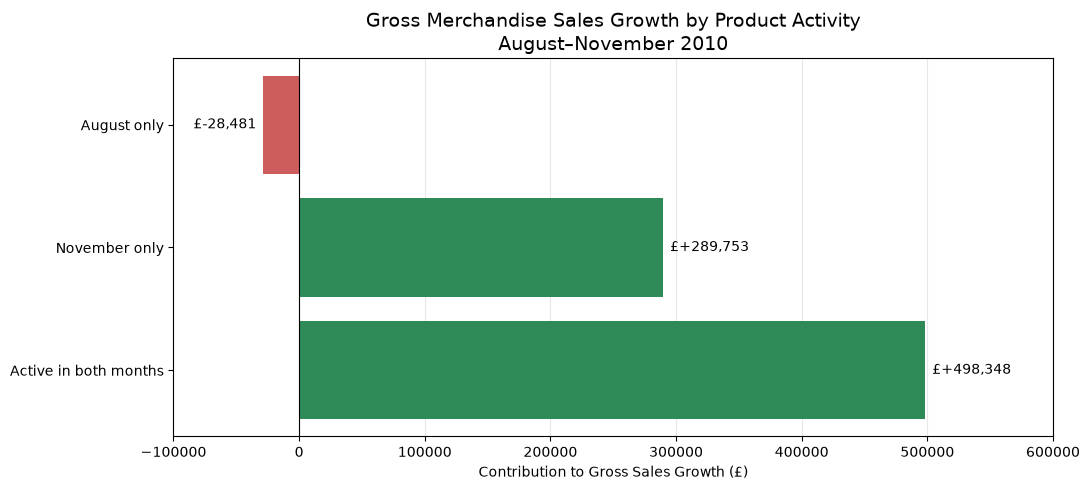

In [28]:
##### Visualise product-group contributions
# Prepare product-group growth chart

chart_values = growth_status_summary["RevenueGrowth"]

colors = [
    "seagreen" if value >= 0 else "indianred"
    for value in chart_values
]

fig, ax = plt.subplots(figsize=(11, 5))

bars = ax.barh(
    chart_values.index,
    chart_values.values,
    color=colors
)

# Add monetary labels
ax.bar_label(
    bars,
    labels=[
        f"£{value:+,.0f}"
        for value in chart_values.values
    ],
    padding=5
)

ax.axvline(0, color="black", linewidth=0.8)

ax.set_title(
    "Gross Merchandise Sales Growth by Product Activity\n"
    "August–November 2010",
    fontsize=14
)

ax.set_xlabel("Contribution to Gross Sales Growth (£)")
ax.set_xlim(-100000, 600000)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


In [29]:
#### Investigate changes in product-level selling prices

# Calculate product-level average selling prices
product_prices = (
    product_data.groupby(
        ["Month", "StockCode"],
        observed=True
    )
    .agg(
        GrossSales=("LineValue", "sum"),
        UnitsSold=("Quantity", "sum")
    )
    .reset_index()
)

# Calculate weighted average selling price
product_prices["AverageSellingPrice"] = (
    product_prices["GrossSales"]
    / product_prices["UnitsSold"]
)

# Compare August and November prices
price_comparison = product_prices.pivot(
    index="StockCode",
    columns="Month",
    values="AverageSellingPrice"
)

# Convert month labels to strings
price_comparison.columns = [
    str(month) for month in price_comparison.columns
]

# Keep products sold in both months
price_comparison = price_comparison.dropna(
    subset=["2010-08", "2010-11"]
)

# Calculate percentage price change
price_comparison["PriceChangePct"] = (
    (
        price_comparison["2010-11"]
        / price_comparison["2010-08"]
    ) - 1
) * 100

print(
    "Products with prices in both months:",
    len(price_comparison)
)

display(price_comparison.head(10).round(2))

Products with prices in both months: 2353


,2010-08,2010-11,PriceChangePct
StockCode,,,
10002,0.77,0.78,1.98
10133,0.85,0.88,3.92
10134,1.08,1.25,16.16
10135,1.25,1.22,-2.20
11001,1.69,1.60,-5.25
15034,0.16,0.14,-12.18
15036,1.13,0.75,-33.69
15039,0.96,0.90,-7.02
16008,0.25,0.25,0.00


In [30]:
##### Classify product-level price changes
# Define tolerance for negligible price differences
tolerance = 0.01

# Classify product-level price changes
price_comparison["PriceStatus"] = np.select(
    [
        price_comparison["PriceChangePct"] > tolerance,
        price_comparison["PriceChangePct"] < -tolerance
    ],
    [
        "Price increased",
        "Price decreased"
    ],
    default="Price unchanged"
)

# Count products in each category
price_status_counts = (
    price_comparison["PriceStatus"].value_counts()
)

# Calculate percentage distribution
price_status_pct = (
    price_status_counts / len(price_comparison) * 100
)

# Create summary
price_status_summary = pd.DataFrame({
    "Products": price_status_counts,
    "Percentage": price_status_pct
})

display(price_status_summary.round(2))

# Validate classification
assert price_status_summary["Products"].sum() == 2353

print("Product price classification passed.")

,Products,Percentage
PriceStatus,,
Price increased,1171,49.77
Price decreased,808,34.34
Price unchanged,374,15.89


Product price classification passed.


In [31]:
##### Calculate a like-for-like price index
# Get August quantities for products sold in both months
august_quantities = product_prices.loc[
    product_prices["Month"].astype(str) == "2010-08",
    ["StockCode", "UnitsSold"]
].set_index("StockCode")["UnitsSold"]

# Join quantities to the matched-product price table
price_index_data = price_comparison.join(
    august_quantities.rename("AugustUnits"),
    how="inner"
)

# Calculate sales value using August quantities
august_basket_value = (
    price_index_data["2010-08"]
    * price_index_data["AugustUnits"]
).sum()

november_prices_august_basket = (
    price_index_data["2010-11"]
    * price_index_data["AugustUnits"]
).sum()

# Calculate like-for-like price change
like_for_like_price_change = (
    november_prices_august_basket
    / august_basket_value - 1
) * 100

print(f"Products compared: {len(price_index_data):,}")
print(f"August basket value: £{august_basket_value:,.2f}")
print(
    "August basket at November prices: "
    f"£{november_prices_august_basket:,.2f}"
)
print(
    f"Like-for-like price change: "
    f"{like_for_like_price_change:.2f}%"
)

Products compared: 2,353
August basket value: £647,579.79
August basket at November prices: £807,806.95
Like-for-like price change: 24.74%


In [32]:
##### Calculate a November-weighted price index

# Get November quantities for matched products
november_quantities = product_prices.loc[
    product_prices["Month"].astype(str) == "2010-11",
    ["StockCode", "UnitsSold"]
].set_index("StockCode")["UnitsSold"]

# Add November quantities
price_index_data = price_index_data.join(
    november_quantities.rename("NovemberUnits"),
    how="inner"
)

# Value November quantities at August prices
november_basket_august_prices = (
    price_index_data["2010-08"]
    * price_index_data["NovemberUnits"]
).sum()

# Value November quantities at November prices
november_basket_november_prices = (
    price_index_data["2010-11"]
    * price_index_data["NovemberUnits"]
).sum()

# Calculate November-weighted price change
november_weighted_price_change = (
    november_basket_november_prices
    / november_basket_august_prices - 1
) * 100

print(
    "November basket at August prices: "
    f"£{november_basket_august_prices:,.2f}"
)
print(
    "November basket at November prices: "
    f"£{november_basket_november_prices:,.2f}"
)
print(
    "November-weighted price change: "
    f"{november_weighted_price_change:.2f}%"
)

November basket at August prices: £1,135,646.72
November basket at November prices: £1,145,927.48
November-weighted price change: 0.91%


In [33]:
##### Calculate a symmetric price index

# Convert percentage changes into index ratios
august_price_index = (
    1 + like_for_like_price_change / 100
)

november_price_index = (
    1 + november_weighted_price_change / 100
)

# Calculate Fisher-style price index
fisher_price_index = np.sqrt(
    august_price_index * november_price_index
)

fisher_price_change = (
    fisher_price_index - 1
) * 100

# Display results
print(
    f"August-weighted price change: "
    f"{like_for_like_price_change:.2f}%"
)

print(
    f"November-weighted price change: "
    f"{november_weighted_price_change:.2f}%"
)

print(
    f"Fisher-style price change: "
    f"{fisher_price_change:.2f}%"
)


August-weighted price change: 24.74%
November-weighted price change: 0.91%
Fisher-style price change: 12.19%


In [34]:
#### Compare the first nine days of December
# Select December 1–9 for both years

december_data = revenue_data.loc[
    (revenue_data["InvoiceDate"].dt.month == 12) &
    (revenue_data["InvoiceDate"].dt.day <= 9) &
    (revenue_data["InvoiceDate"].dt.year.isin([2009, 2010]))
].copy()

# Calculate net merchandise revenue by year
december_comparison = (
    december_data.groupby(
        december_data["InvoiceDate"].dt.year
    )["LineValue"]
    .sum()
)

display(december_comparison)

# Calculate year-on-year growth
december_yoy = (
    december_comparison.loc[2010] /
    december_comparison.loc[2009] - 1
) * 100

print(f"December 1–9 YoY growth: {december_yoy:.2f}%")

InvoiceDate
2009    379912.92
2010    402363.51
Name: LineValue, dtype: float64

December 1–9 YoY growth: 5.91%


In [35]:
#### Compare December's daily revenue
# Compare daily net merchandise revenue
december_daily = (
    december_data.assign(
        Year=december_data["InvoiceDate"].dt.year,
        Day=december_data["InvoiceDate"].dt.day
    )
    .groupby(["Day", "Year"])["LineValue"]
    .sum()
    .unstack("Year", fill_value=0)
)

# Calculate daily year-on-year differences
december_daily["YoY_Difference"] = (
    december_daily[2010] - december_daily[2009]
)

display(december_daily.round(2))

# Validate totals
assert np.isclose(
    december_daily[2009].sum(), 379912.92
)

assert np.isclose(
    december_daily[2010].sum(), 402363.51
)

print("December daily revenue validation passed.")

Year,2009,2010,YoY_Difference
Day,,,
1,51303.09,57328.60,6025.51
2,61551.68,46174.28,-15377.40
3,69223.81,43510.73,-25713.08
4,39150.26,0.00,-39150.26
5,9803.05,30957.28,21154.23
6,24179.20,50907.56,26728.36
7,42688.01,81131.02,38443.01
8,43012.62,43375.58,362.96
9,39001.20,48978.46,9977.26


December daily revenue validation passed.


In [36]:
##### Check transaction coverage by date
# Check transaction coverage for December 1–9
december_coverage = (
    df_classified.loc[
        (df_classified["InvoiceDate"].dt.month == 12) &
        (df_classified["InvoiceDate"].dt.day <= 9) &
        (df_classified["InvoiceDate"].dt.year.isin([2009, 2010]))
    ]
    .assign(
        Date=lambda x: x["InvoiceDate"].dt.normalize()
    )
    .groupby("Date")
    .agg(
        Rows=("Invoice", "size"),
        UniqueInvoices=("Invoice", "nunique")
    )
)

# Include dates with no transactions
all_dates = (
    pd.date_range("2009-12-01", "2009-12-09")
    .append(
        pd.date_range("2010-12-01", "2010-12-09")
    )
)

december_coverage = (
    december_coverage
    .reindex(all_dates, fill_value=0)
)

december_coverage["Weekday"] = (
    december_coverage.index.day_name()
)

display(december_coverage)

,Rows,UniqueInvoices,Weekday
2009-12-01,3223,166,Tuesday
2009-12-02,3277,133,Wednesday
2009-12-03,3002,150,Thursday
2009-12-04,2559,107,Friday
2009-12-05,402,32,Saturday
2009-12-06,1942,90,Sunday
2009-12-07,2869,123,Monday
2009-12-08,2440,170,Tuesday
2009-12-09,2470,114,Wednesday
2010-12-01,3108,143,Wednesday


In [37]:
##### Transaction coverage findings

# Add year and weekday information
december_weekdays = december_data.copy()

december_weekdays["Year"] = (
    december_weekdays["InvoiceDate"].dt.year
)

december_weekdays["Weekday"] = (
    december_weekdays["InvoiceDate"].dt.day_name()
)

# Calculate revenue by weekday and year
weekday_revenue = (
    december_weekdays.groupby(
        ["Weekday", "Year"]
    )["LineValue"]
    .sum()
    .unstack("Year", fill_value=0)
)

# Arrange weekdays in calendar order
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_revenue = weekday_revenue.reindex(
    weekday_order,
    fill_value=0
)

display(weekday_revenue.round(2))

# Validate totals
assert np.isclose(
    weekday_revenue[2009].sum(),
    379912.92
)

assert np.isclose(
    weekday_revenue[2010].sum(),
    402363.51
)

print("Weekday revenue validation passed.")

Year,2009,2010
Weekday,,
Monday,42688.01,50907.56
Tuesday,94315.71,81131.02
Wednesday,100552.88,100704.18
Thursday,69223.81,95152.74
Friday,39150.26,43510.73
Saturday,9803.05,0.00
Sunday,24179.20,30957.28


Weekday revenue validation passed.


In [38]:
##### Calculate weekday-adjusted revenue growth
# Count weekday occurrences in each comparison period
dates_2009 = pd.date_range("2009-12-01", "2009-12-09")
dates_2010 = pd.date_range("2010-12-01", "2010-12-09")

weekday_counts = pd.DataFrame({
    2009: dates_2009.day_name().value_counts(),
    2010: dates_2010.day_name().value_counts()
}).reindex(weekday_order, fill_value=0)

# Calculate average revenue per weekday occurrence
weekday_daily_average = (
    weekday_revenue / weekday_counts
)

# Use the average weekday distribution across both years
standard_weights = weekday_counts.mean(axis=1)

# Calculate standardised revenue for each year
adjusted_revenue = (
    weekday_daily_average
    .mul(standard_weights, axis=0)
    .sum()
)

# Calculate adjusted year-on-year growth
adjusted_yoy = (
    adjusted_revenue.loc[2010]
    / adjusted_revenue.loc[2009] - 1
) * 100

print("Weekday occurrence counts:")
display(weekday_counts)

print("\nWeekday-adjusted revenue:")
display(adjusted_revenue.round(2))

print(f"\nUnadjusted YoY growth: {december_yoy:.2f}%")
print(f"Weekday-adjusted YoY growth: {adjusted_yoy:.2f}%")

Weekday occurrence counts:


,2009,2010
Monday,1,1
Tuesday,2,1
Wednesday,2,2
Thursday,1,2
Friday,1,1
Saturday,1,1
Sunday,1,1



Weekday-adjusted revenue:


Year
2009    390945.90
2010    419140.84
dtype: float64


Unadjusted YoY growth: 5.91%
Weekday-adjusted YoY growth: 7.21%


In [39]:
##### Validate the weekday-adjusted calculation
# Validate the weekday-standardisation method

print(
    "Standardised number of days:",
    standard_weights.sum()
)

print(
    "Adjusted revenue difference: "
    f"£{adjusted_revenue.loc[2010] - adjusted_revenue.loc[2009]:,.2f}"
)

print(
    "Adjusted YoY growth: "
    f"{adjusted_yoy:.2f}%"
)

# Validation checks
assert np.isclose(standard_weights.sum(), 9)

assert np.isclose(
    adjusted_yoy,
    (
        adjusted_revenue.loc[2010]
        / adjusted_revenue.loc[2009] - 1
    ) * 100
)

print("Weekday adjustment validation passed.")

Standardised number of days: 9.0
Adjusted revenue difference: £28,194.94
Adjusted YoY growth: 7.21%
Weekday adjustment validation passed.


In [40]:
#### Validate the weekday-adjusted calculation

# Validate the weekday-standardisation method

print(
    "Standardised number of days:",
    standard_weights.sum()
)

print(
    "Adjusted revenue difference: "
    f"£{adjusted_revenue.loc[2010] - adjusted_revenue.loc[2009]:,.2f}"
)

print(
    "Adjusted YoY growth: "
    f"{adjusted_yoy:.2f}%"
)

# Validation checks
assert np.isclose(standard_weights.sum(), 9)

assert np.isclose(
    adjusted_yoy,
    (
        adjusted_revenue.loc[2010]
        / adjusted_revenue.loc[2009] - 1
    ) * 100
)

print("Weekday adjustment validation passed.")

Standardised number of days: 9.0
Adjusted revenue difference: £28,194.94
Adjusted YoY growth: 7.21%
Weekday adjustment validation passed.


In [41]:
#### create the december_summary variable

december_summary = pd.DataFrame({
    "Metric": [
        "December 2009 revenue (days 1–9)",
        "December 2010 revenue (days 1–9)",
        "Unadjusted YoY growth (%)",
        "Weekday-adjusted 2009 revenue",
        "Weekday-adjusted 2010 revenue",
        "Weekday-adjusted YoY growth (%)",
        "Adjusted revenue difference"
    ],
    "Value": [
        december_comparison.loc[2009],
        december_comparison.loc[2010],
        december_yoy,
        adjusted_revenue.loc[2009],
        adjusted_revenue.loc[2010],
        adjusted_yoy,
        adjusted_revenue.loc[2010] - adjusted_revenue.loc[2009]
    ]
})

display(december_summary.round(2))

print("December analysis summary created.")


,Metric,Value
0,December 2009 revenue (days 1–9),379912.92
1,December 2010 revenue (days 1–9),402363.51
2,Unadjusted YoY growth (%),5.91
3,Weekday-adjusted 2009 revenue,390945.90
4,Weekday-adjusted 2010 revenue,419140.84
5,Weekday-adjusted YoY growth (%),7.21
6,Adjusted revenue difference,28194.94


December analysis summary created.


In [42]:
##### Return to August–November price analysis
# Calculate Fisher price index

august_price_index = (
    1 + like_for_like_price_change / 100
)

november_price_index = (
    1 + november_weighted_price_change / 100
)

fisher_price_index = np.sqrt(
    august_price_index * november_price_index
)

fisher_price_change = (
    fisher_price_index - 1
) * 100

print(
    f"August-weighted price change: "
    f"{like_for_like_price_change:.2f}%"
)

print(
    f"November-weighted price change: "
    f"{november_weighted_price_change:.2f}%"
)

print(
    f"Fisher price change: "
    f"{fisher_price_change:.2f}%"
)

August-weighted price change: 24.74%
November-weighted price change: 0.91%
Fisher price change: 12.19%


In [43]:
#### Calculate the product-mix effect for matched products
# Calculate total units for matched products
august_units = price_index_data["AugustUnits"].sum()
november_units = price_index_data["NovemberUnits"].sum()

# Calculate observed average sales value per unit
august_avg_unit_value = (
    august_basket_value / august_units
)

november_avg_unit_value = (
    november_basket_november_prices / november_units
)

# Overall unit-value index for matched products
unit_value_index = (
    november_avg_unit_value / august_avg_unit_value
)

# Residual product-mix index
product_mix_index = (
    unit_value_index / fisher_price_index
)

# Display results
print(f"Matched products: {len(price_index_data):,}")

print(
    f"August average unit value: "
    f"£{august_avg_unit_value:.4f}"
)

print(
    f"November average unit value: "
    f"£{november_avg_unit_value:.4f}"
)

print(
    f"Average unit-value change: "
    f"{(unit_value_index - 1) * 100:.2f}%"
)

print(
    f"Fisher price change: "
    f"{fisher_price_change:.2f}%"
)

print(
    f"Residual product-mix change: "
    f"{(product_mix_index - 1) * 100:.2f}%"
)

# Validate multiplicative decomposition
assert np.isclose(
    unit_value_index,
    fisher_price_index * product_mix_index
)

print("Price and mix decomposition passed.")

Matched products: 2,353
August average unit value: £1.5408
November average unit value: £1.8646
Average unit-value change: 21.01%
Fisher price change: 12.19%
Residual product-mix change: 7.86%
Price and mix decomposition passed.


In [44]:
#### Measure the contribution of product assortment
# Calculate overall average sales value per unit
overall_unit_values = (
    sales_volume.loc[
        sales_volume["Month"].astype(str).isin(
            ["2010-08", "2010-11"]
        )
    ]
    .groupby("Month", observed=True)
    .agg(
        GrossSales=("LineValue", "sum"),
        UnitsSold=("Quantity", "sum")
    )
)

overall_unit_values["AverageUnitValue"] = (
    overall_unit_values["GrossSales"]
    / overall_unit_values["UnitsSold"]
)

# Calculate overall growth
overall_august = overall_unit_values.loc[
    "2010-08", "AverageUnitValue"
]

overall_november = overall_unit_values.loc[
    "2010-11", "AverageUnitValue"
]

overall_unit_growth = (
    overall_november / overall_august - 1
) * 100

# Compare with matched products
print(f"Overall August unit value: £{overall_august:.4f}")
print(f"Overall November unit value: £{overall_november:.4f}")
print(f"Overall unit-value growth: {overall_unit_growth:.2f}%")

print(
    f"Matched-product unit-value growth: "
    f"{(unit_value_index - 1) * 100:.2f}%"
)

print(
    f"Difference in growth rates: "
    f"{overall_unit_growth - (unit_value_index - 1) * 100:.2f}"
    " percentage points"
)

Overall August unit value: £1.4294
Overall November unit value: £1.9733
Overall unit-value growth: 38.05%
Matched-product unit-value growth: 21.01%
Difference in growth rates: 17.04 percentage points


In [45]:
##### Analyse August-only and November-only products

# Create a lookup of product activity status
product_status_lookup = product_growth["ProductStatus"]

# Assign each sales transaction to its product group
assortment_data = product_data.copy()

assortment_data["ProductStatus"] = (
    assortment_data["StockCode"].map(
        product_status_lookup
    )
)

# Summarise sales and quantities by month and group
assortment_summary = (
    assortment_data.groupby(
        ["Month", "ProductStatus"],
        observed=True
    )
    .agg(
        GrossSales=("LineValue", "sum"),
        UnitsSold=("Quantity", "sum")
    )
    .reset_index()
)

# Calculate average sales value per unit
assortment_summary["AverageUnitValue"] = (
    assortment_summary["GrossSales"]
    / assortment_summary["UnitsSold"]
)

display(assortment_summary.round(4))

# Validate monthly sales totals
for month in ["2010-08", "2010-11"]:
    calculated = assortment_summary.loc[
        assortment_summary["Month"].astype(str) == month,
        "GrossSales"
    ].sum()

    expected = overall_unit_values.loc[
        month, "GrossSales"
    ]

    assert np.isclose(calculated, expected)

print("Product assortment validation passed.")

,Month,ProductStatus,GrossSales,UnitsSold,AverageUnitValue
0,2010-08,Active in both months,647579.790,420279,1.5408
1,2010-08,August only,28480.930,52692,0.5405
2,2010-11,Active in both months,1145927.480,614580,1.8646
3,2010-11,November only,289752.642,112973,2.5648


Product assortment validation passed.


In [46]:
#### Quantify the assortment contribution
# Calculate matched-product shares of total units
august_matched_share = 420279 / 472971
november_matched_share = 614580 / 727553

# Calculate contributions from matched products
matched_contribution = (
    november_matched_share * 1.8646
    - august_matched_share * 1.5408
)

# Calculate contributions from exclusive products
exclusive_contribution = (
    (112973 / 727553) * 2.5648
    - (52692 / 472971) * 0.5405
)

# Compare with overall change
total_unit_value_change = (
    overall_november - overall_august
)

print(
    f"Matched-product contribution: "
    f"£{matched_contribution:.4f}"
)

print(
    f"Exclusive-product contribution: "
    f"£{exclusive_contribution:.4f}"
)

print(
    f"Overall unit-value change: "
    f"£{total_unit_value_change:.4f}"
)

print(
    f"Combined contributions: "
    f"£{matched_contribution + exclusive_contribution:.4f}"
)

Matched-product contribution: £0.2059
Exclusive-product contribution: £0.3380
Overall unit-value change: £0.5439
Combined contributions: £0.5440


In [47]:
#### Recalculate using exact values
# Use exact sales and quantities from the assortment summary
a = assortment_summary.copy()
a["Month"] = a["Month"].astype(str)

# Contribution to overall unit value for each group
a["TotalMonthUnits"] = a.groupby("Month")["UnitsSold"].transform("sum")

a["UnitValueContribution"] = (
    a["GrossSales"] / a["TotalMonthUnits"]
)

# Extract matched-product contributions
matched_aug = a.loc[
    (a["Month"] == "2010-08") &
    (a["ProductStatus"] == "Active in both months"),
    "UnitValueContribution"
].iloc[0]

matched_nov = a.loc[
    (a["Month"] == "2010-11") &
    (a["ProductStatus"] == "Active in both months"),
    "UnitValueContribution"
].iloc[0]

matched_effect = matched_nov - matched_aug

# Exclusive-product contribution
exclusive_aug = a.loc[
    (a["Month"] == "2010-08") &
    (a["ProductStatus"] == "August only"),
    "UnitValueContribution"
].iloc[0]

exclusive_nov = a.loc[
    (a["Month"] == "2010-11") &
    (a["ProductStatus"] == "November only"),
    "UnitValueContribution"
].iloc[0]

exclusive_effect = exclusive_nov - exclusive_aug

# Exact reconciliation
total_effect = matched_effect + exclusive_effect

print(f"Matched-product contribution: £{matched_effect:.6f}")
print(f"Exclusive-product contribution: £{exclusive_effect:.6f}")
print(f"Overall unit-value change: £{total_effect:.6f}")

print(
    f"Matched contribution share: "
    f"{matched_effect / total_effect * 100:.2f}%"
)
print(
    f"Exclusive contribution share: "
    f"{exclusive_effect / total_effect * 100:.2f}%"
)

assert np.isclose(
    total_effect,
    overall_november - overall_august
)

print("Exact assortment decomposition passed.")

Matched-product contribution: £0.205869
Exclusive-product contribution: £0.338039
Overall unit-value change: £0.543908
Matched contribution share: 37.85%
Exclusive contribution share: 62.15%
Exact assortment decomposition passed.


In [48]:
### Create the final decomposition summary
# Create a reconciled unit-value decomposition summary

unit_value_summary = pd.DataFrame({
    "Component": [
        "Matched products",
        "August-only / November-only products",
        "Total change"
    ],
    "Contribution_GBP_Per_Unit": [
        matched_effect,
        exclusive_effect,
        total_effect
    ]
})

unit_value_summary["Share_Pct"] = (
    unit_value_summary["Contribution_GBP_Per_Unit"]
    / total_effect * 100
)

display(unit_value_summary.round(4))

# Validate the component shares
assert np.isclose(
    unit_value_summary.loc[:1, "Share_Pct"].sum(),
    100
)

print("Unit-value decomposition summary passed.")

,Component,Contribution_GBP_Per_Unit,Share_Pct
0,Matched products,0.2059,37.8499
1,August-only / November-only products,0.3380,62.1501
2,Total change,0.5439,100.0000


Unit-value decomposition summary passed.


In [49]:
##### Consolidate our key findings
# Consolidate key business findings

business_findings = pd.DataFrame({
    "Metric": [
        "August 2010 gross merchandise sales (£)",
        "November 2010 gross merchandise sales (£)",
        "Gross merchandise sales growth (%)",
        "Units sold growth (%)",
        "Average sales value per unit growth (%)",
        "Matched-product Fisher price change (%)",
        "Matched-product residual mix change (%)",
        "Exclusive-product contribution share (%)",
        "December 1–9 unadjusted YoY growth (%)",
        "December 1–9 weekday-adjusted YoY growth (%)"
    ],
    "Value": [
        676060.72,
        1435680.12,
        (1435680.12 / 676060.72 - 1) * 100,
        (727553 / 472971 - 1) * 100,
        overall_unit_growth,
        fisher_price_change,
        (product_mix_index - 1) * 100,
        exclusive_effect / total_effect * 100,
        december_yoy,
        adjusted_yoy
    ]
})

display(business_findings.round(2))

print("Business findings consolidated.")

,Metric,Value
0,August 2010 gross merchandise sales (£),676060.72
1,November 2010 gross merchandise sales (£),1435680.12
2,Gross merchandise sales growth (%),112.36
3,Units sold growth (%),53.83
4,Average sales value per unit growth (%),38.05
5,Matched-product Fisher price change (%),12.19
6,Matched-product residual mix change (%),7.86
7,Exclusive-product contribution share (%),62.15
8,December 1–9 unadjusted YoY growth (%),5.91
9,December 1–9 weekday-adjusted YoY growth (%),7.21


Business findings consolidated.


## Executive Summary — Retail Revenue Growth Analysis

### Project Overview

This project explores how retail sales changed between August and November 2010 and what may have contributed to that growth. Rather than focusing only on revenue figures, the analysis examines sales volumes, average selling prices and changes in the products customers purchased.

It also compares the first nine days of December 2009 and 2010 to better understand year-on-year performance during the Christmas shopping period.

### Key Findings

**1. Retail sales more than doubled**

Gross merchandise sales increased from £676,060.72 in August to £1,435,680.12 in November 2010, representing growth of 112.36%.

This was not simply a result of selling more products. The data shows that both the number of units sold and their average sales value increased.

**2. Customers purchased more units at a higher average value**

The number of units sold increased by 53.83%, while average gross sales value per unit rose by 38.05%.

These findings suggest that sales growth was supported by both higher purchasing volumes and changes in the value of the products being sold.

**3. Selling-price changes played a role**

Looking at 2,353 products sold in both August and November, the Fisher price index showed a 12.19% increase in observed average selling prices.

The analysis also identified a 7.86% residual product-mix increase, suggesting that changes in the quantities purchased across different products contributed to higher average unit values.

**4. Product assortment was an important factor**

One of the most interesting findings came from comparing products sold in both months with those sold in only one month.

Products sold exclusively in August or November accounted for a net 62.15% of the overall increase in average sales value per unit.

This highlights the importance of examining which products customers purchased, rather than looking at total sales alone.

**5. December sales showed positive year-on-year growth**

Net merchandise revenue for December 1–9 increased by 5.91% between 2009 and 2010.

After adjusting for differences in weekday composition, estimated growth increased to 7.21%.

This provides a more balanced comparison, although the absence of recorded transactions on December 4, 2010 remains a limitation.

### What These Findings Mean for the Business

The analysis suggests that retail sales growth was associated with three factors: customers purchasing more units, changes in observed selling prices and shifts in the types of products sold.

Product assortment stands out as an area worth investigating further. In particular, products sold in November but not August had a higher average sales value per unit than products sold exclusively in August.

Understanding these differences could help a retailer make more informed decisions about inventory planning, product selection and seasonal sales strategies.

### Limitations

There are several points to consider when interpreting the results.

Gross merchandise sales and net merchandise revenue are different measures, and the analysis keeps them separate.

December 2010 contains transactions only up to December 9, so comparing it directly with a complete month would be misleading. There were also no recorded transactions on December 4, 2010.

Finally, changes in observed selling prices may reflect discounts, customer purchasing patterns or transaction conditions. The findings identify relationships within the data but do not prove that any single factor caused the increase in sales.

### Conclusion

The main takeaway from this project is that **retail growth is not just about selling more products. What customers buy, how much they purchase and the prices they pay all matter.**

By examining these factors separately, the analysis provides a clearer picture of the changes behind the retailer's sales performance and identifies areas for further investigation.